# LoRA study: results

Loads the finished runs from `results/runs/` (produced by `python -m peft_study.train`) and shows:
1. the comparison table,
2. accuracy vs trainable parameters,
3. storage per task,
4. training curves,
5. live predictions with a saved 3 MB LoRA adapter on top of the shared DistilBERT base.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from peft_study import report
%matplotlib inline

runs = report.load_runs()
print(f"{len(runs)} runs | train size {runs[0]['train_size']:,} | epochs {runs[0]['epochs']} | max_len {runs[0]['max_len']} | {runs[0]['base_model']}")
display(Markdown(report.table(runs)))

6 runs | train size 3,999 | epochs 3 | max_len 64 | distilbert-base-uncased


| Method | Trainable params | Trainable % | Test accuracy | Test macro F1 | Gap to full FT (acc) | Stored per task | Train time |
|---|---|---|---|---|---|---|---|
| Head only (frozen encoder) | 595K | 0.89% | 54.8% | 0.309 | -36.8 pt | 2.3 MB | 27.1 min |
| LoRA r=2 (attention q,v) | 632K | 0.95% | 83.1% | 0.767 | -8.4 pt | 2.4 MB | 28.5 min |
| LoRA r=8 (attention q,v) | 743K | 1.12% | 86.1% | 0.801 | -5.4 pt | 2.8 MB | 27.3 min |
| LoRA r=32 (attention q,v) | 1.19M | 1.77% | 89.3% | 0.837 | -2.2 pt | 4.5 MB | 27.2 min |
| LoRA r=8 (all linear layers) | 1.26M | 1.88% | 90.3% | 0.851 | -1.2 pt | 4.8 MB | 43.7 min |
| Full fine-tuning | 66.96M | 100.00% | 91.5% | 0.870 | — | 255.4 MB | 63.7 min |


## Accuracy vs trainable parameters

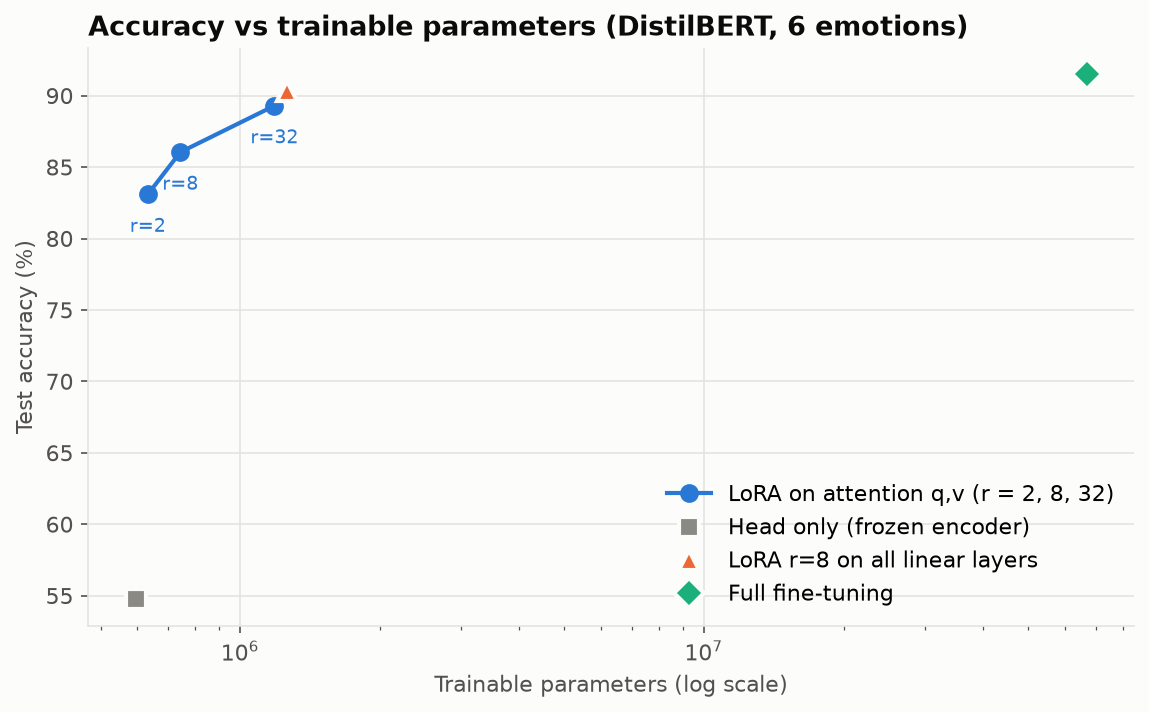

In [2]:
report.tradeoff_figure(runs, pathlib.Path("../results/figures/accuracy_vs_trainable_params.png"))
from IPython.display import Image
Image("../results/figures/accuracy_vs_trainable_params.png")

## What you store per task

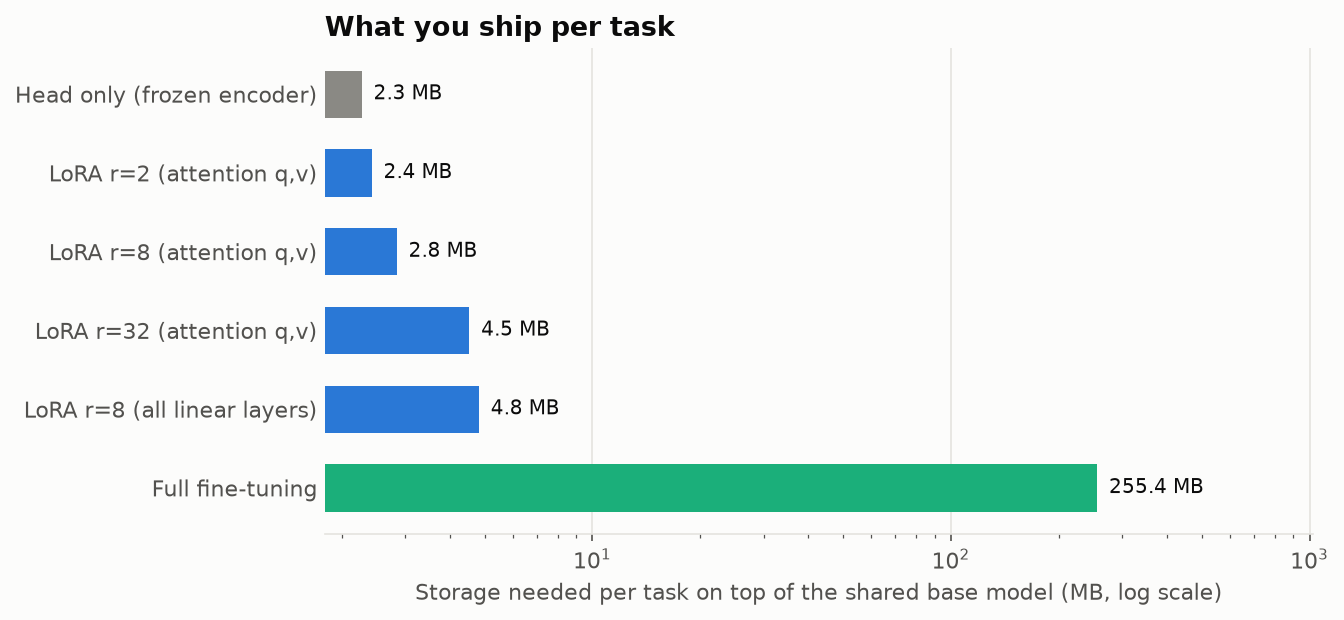

In [3]:
report.storage_figure(runs, pathlib.Path("../results/figures/storage_per_task.png"))
Image("../results/figures/storage_per_task.png")

## Per-class F1 (test set)

In [4]:
per_class = pd.DataFrame({r["label"]: r["test"]["per_class_f1"] for r in runs}).T
per_class.round(3)

,anger,fear,joy,love,sadness,surprise
Head only (frozen encoder),0.290,0.279,0.688,0.000,0.598,0.000
"LoRA r=2 (attention q,v)",0.784,0.785,0.898,0.636,0.854,0.645
"LoRA r=8 (attention q,v)",0.820,0.814,0.912,0.730,0.889,0.643
"LoRA r=32 (attention q,v)",0.895,0.877,0.922,0.734,0.926,0.672
LoRA r=8 (all linear layers),0.913,0.862,0.929,0.780,0.940,0.682
Full fine-tuning,0.918,0.877,0.941,0.796,0.949,0.738


## Training curves (validation accuracy per epoch)

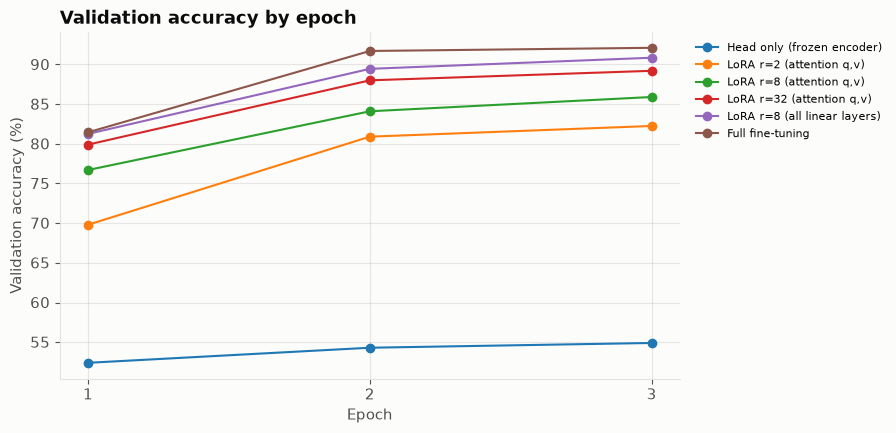

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for r in runs:
    h = r["history"]
    ax.plot([e["epoch"] for e in h], [100 * e["val_accuracy"] for e in h], "-o", label=r["label"])
ax.set_xlabel("Epoch"); ax.set_ylabel("Validation accuracy (%)"); ax.set_xticks([1, 2, 3])
ax.grid(alpha=0.3); ax.legend(fontsize=8, frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_title("Validation accuracy by epoch", loc="left", fontweight="bold")
plt.show()

## Live predictions with a saved adapter

The base DistilBERT is shared; only the small adapter folder (`adapters/lora_r8_qv`) is task-specific.

In [6]:
from peft_study.predict import load, predict

tok, model = load("lora_r8_qv")
texts = [
    "i feel so happy and grateful for my friends today",
    "i am terrified of walking home alone at night",
    "i am so annoyed that they cancelled my order again",
    "i was shocked to find out they planned a party for me",
    "i feel lonely and miserable without you",
    "i love spending quiet evenings with my partner",
]
rows = []
for t, p in zip(texts, predict(texts, tok, model)):
    top = max(p, key=p.get)
    rows.append({"text": t, "prediction": top, "confidence": f"{p[top]:.1%}"})
pd.DataFrame(rows)

C:\Users\Arsla\.venvs\nlp\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Loading weights:  21%|██        | 21/100 [00:00<00:00, 196.82it/s]

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 579.62it/s]


[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,text,prediction,confidence
0,i feel so happy and grateful for my friends today,joy,99.5%
1,i am terrified of walking home alone at night,fear,98.8%
2,i am so annoyed that they cancelled my order a...,anger,99.7%
3,i was shocked to find out they planned a party...,surprise,90.2%
4,i feel lonely and miserable without you,sadness,99.6%
5,i love spending quiet evenings with my partner,sadness,44.6%
